### Langchain Version V1

In [6]:
import os 
from dotenv import load_dotenv
load_dotenv()
 
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [10]:
import requests

url = "https://leetcode-api-pied.vercel.app/user/amitsah04v/solved"
try:
    response=requests.get(url)
    if response.status_code == 200:
        data = response.json()
        print("Success")
    else:
        print("Server Error: {response.status_code}")
except requests.exceptions.RequestException as e:
    print("Network error: {e}")
    
print(data["solved_slugs"])

Success
['gas-station', 'add-two-numbers', 'median-of-two-sorted-arrays', 'count-days-spent-together', 'reorder-list', 'merge-k-sorted-lists', 'merge-two-sorted-lists', 'swap-nodes-in-pairs', 'task-scheduler', 'employee-bonus', 'non-overlapping-intervals', 'prime-subset-selection-i', 'three-fibonacci-sum', 'valid-anagram', 'partition-labels', 'merge-intervals', 'insert-interval', 'remove-outermost-parentheses', 'minimum-remove-to-make-valid-parentheses']


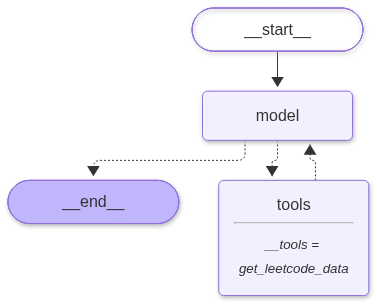

In [ ]:
from langchain_ollama import ChatOllama
from langchain.agents import create_agent

llm = ChatOllama(model="llama3.2", num_predict=300)

def get_leetcode_data(profile: str):
    """
    Get the leetcode profile {data} question is about 
    keep the max tokens to 300
    """
    return f"the what these leetcode question is about "

agent = create_agent(
    model=llm,
    tools=[get_leetcode_data],
    system_prompt="You are a helpful assistant"    
)

agent

In [ ]:
import requests
from langchain_ollama import ChatOllama
from langchain.agents import create_agent

llm = ChatOllama(model="llama3.2", num_predict=300)

def get_leetcode_data(username: str) -> str:
    """Fetch the number of problems a LeetCode user has solved.

    Args:
        username: The LeetCode username (e.g. "neetcode").
    """
    r = requests.get(
        f"https://leetcode-api-pied.vercel.app/user/{username}/solved",
        timeout=10,
    )
    r.raise_for_status()
    return r.text

agent = create_agent(
    model=llm,
    tools=[get_leetcode_data],
    system_prompt="You are a helpful assistant. Use the tool to look up LeetCode profiles.",
)

result = agent.invoke(
    {"messages": [{"role": "user", "content": "How many problems has amitsah04v solved?"}]}
)
print(result["messages"])

[HumanMessage(content='How many problems has amitsah04v solved?', additional_kwargs={}, response_metadata={}, id='f498e4e6-f915-4bb2-830a-7feb81c9015d'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2', 'created_at': '2026-10-31T13:19:21.474828Z', 'done': True, 'done_reason': 'stop', 'total_duration': 596413459, 'load_duration': 7291000, 'prompt_eval_count': 204, 'prompt_eval_duration': 64923000, 'eval_count': 19, 'eval_duration': 473407000, 'logprobs': None, 'model_name': 'llama3.2', 'model_provider': 'ollama'}, id='lc_run--01a1921d-5f29-7405-967d-1db226dd99a7-0', tool_calls=[{'name': 'get_leetcode_data', 'args': {'username': 'amitsah04v'}, 'id': '1faf3634-67f3-4d99-ac53-f1281e08a4cc', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 204, 'output_tokens': 19, 'total_tokens': 223}), ToolMessage(content='{"username":"amitsah04v","total_solved":19,"solved_slugs":["gas-station","add-two-numbers","median-of-two-sorted-arrays",